# Regularization, Variable Selection and Dimensionality Reduction

**Chapter 9 — Statistics for Artificial Intelligence (Undergraduate Year 2)**

This notebook follows the flow of the chapter. It runs from top to bottom. Each part ends with a **Key takeaways** section.

**Objectives**
- Understand why an overly complex model generalizes poorly.
- Identify useful, useless and redundant variables.
- Understand regularization and distinguish Ridge from Lasso.
- Understand the goal of dimensionality reduction and compute a PCA.

**Prerequisites**: linear regression, mean, variance, standard deviation, basic knowledge of Python and pandas.

**Libraries**: `numpy`, `pandas`, `matplotlib`, `seaborn`, and `scikit-learn` (used only to check our computations).

**Contents**
- Part 0: Data preparation
- Part 1: Why simplify a model?
- Part 2: Variable selection
- Part 3: Regularization (Ridge and Lasso)
- Part 4: Dimensionality reduction and PCA
- Part 5: Summary

## Part 0: Data preparation

### The dataset for correlation-based selection

| Variable | Meaning |
|---|---|
| `Superficie` | Area in m² |
| `Chambres` | Number of bedrooms, roughly proportional to the area |
| `Age` | Age of the property, in years |
| `Distance_Centre` | Distance to the city center, in km |
| `Superficie_pieds` | Same area, in square feet, with a small measurement noise: **redundant variable** |
| `Bruit_1` to `Bruit_6` | Random numbers unrelated to the price: **useless variables** |
| `Prix` | Variable to explain (target) |

In [21]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.precision", 3)

In [22]:
df = pd.read_csv("data.csv")
df.head()

,Superficie,Chambres,Age,Distance_Centre,Superficie_pieds,Bruit_1,Bruit_2,Bruit_3,Bruit_4,Bruit_5,Bruit_6,Prix
0,163.83,5.0,5.43,19.41,1764.40,0.23,0.74,0.37,0.63,-1.40,0.33,300.36
1,110.22,3.0,53.82,19.70,1186.86,-0.30,-0.48,0.87,1.48,1.79,1.31,115.56
2,177.38,5.0,1.74,6.12,1909.28,-0.11,0.35,0.77,0.12,0.13,0.82,411.95
3,151.58,4.0,14.45,14.81,1631.72,-0.06,-0.73,-0.41,0.63,0.00,0.34,317.09
4,55.07,2.0,8.58,15.12,592.78,0.67,-0.37,0.76,0.38,-1.23,1.44,95.03


### Training / test split

A model must be evaluated on data it has **not** seen during training. We keep 80% of the data for training and 20% for testing. The split is fixed by a seed (`seed`) so that the results are reproducible.

In [23]:
X = df.drop(columns="Prix")
y = df.Prix

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=0.2, 
    random_state=42
)

print(f"Training set: {len(X_train)}")
print(f"Test set: {len(X_test)}")

Training set: 160
Test set: 40


### Error function

The mean squared error (MSE) measures the average gap between the actual values and the predictions:

$$
\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

The smaller the MSE, the better the predictions.

In [24]:
def mse(y_true, y_pred):

    n = len(y_true)
    squared_error = (y_true - y_pred) ** 2
    total = 0
    for i in squared_error:
        total += i

    return total / n
    # return np.mean((y_true - y_pred) ** 2)

## Part 1: Why simplify a model?

### 1.1 Complexity and overfitting

A more complex model fits the training data better. But if it also fits the **noise**, it risks predicting new data poorly. This phenomenon is called **overfitting**.

### 1.2 Generalization

The error on the training data always decreases as complexity increases. The error on the **test data** first decreases, then rises sharply. The model has then learned the noise of the training sample.

The ability of a model to predict new data well is called **generalization**. It is what matters, not the training error.

The opposite phenomenon, a model that is too simple and fails to capture the structure of the data, is called **underfitting**.

**Key takeaways**
- An overly complex model learns the noise and generalizes poorly.
- A model is judged on test data, never on its training data alone.
- Regularization and variable selection are used to reduce complexity.

## Part 2: Variable selection

The goal is to keep the useful variables, discard the useless ones, and keep only one variable among the redundant ones.

### 2.1 Pearson correlation

Pearson correlation measures the strength of a **linear** relationship between two variables. It ranges between -1 and 1:

$$
r(x, y) = \frac{\sum_{i}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i}(x_i - \bar{x})^2 \sum_{i}(y_i - \bar{y})^2}}
$$

A value close to 1 or -1 indicates a strong relationship, and a value close to 0 a weak or nonexistent one.

We compute the correlation with the formula, then check the result with `np.corrcoef`. All the analyses in this part use the training data only.

In [25]:
def correlation(x, y):
    x_c = x - x.mean()
    y_c = y - y.mean()
    return (x_c @ y_c) / np.sqrt((x_c @ x_c) * (y_c @ y_c))

print("Our function :", round(correlation(X_train["Superficie"].to_numpy(), y_train.to_numpy()), 4))
print("np.corrcoef  :", round(np.corrcoef(X_train["Superficie"], y_train)[0, 1], 4))

Our function : 0.9044
np.corrcoef  : 0.9044


### 2.2 Redundant variables

Two redundant variables carry the same information. Keeping both does not improve the model and makes the coefficients unstable. We visualize the correlation matrix between the explanatory variables.

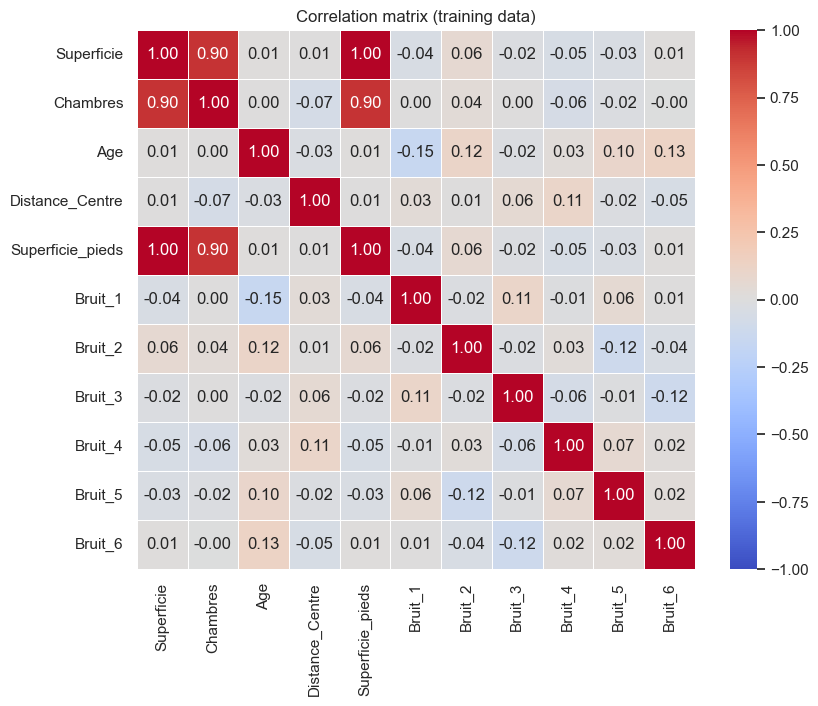

In [26]:
from feature_correlation import FeatureCorrelation

# corr_matrix = X_train.corr()
fc = FeatureCorrelation(X, 0.95)
corr_matrix = fc.obtenir_matrice()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation matrix (training data)")
plt.show()

We remove a variable when it is correlated above a given threshold (95%, for example) with a variable that has already been kept. The threshold is a choice: the lower it is, the more variables are removed. The correlation between `Superficie` and `Chambres` is high but below this threshold: these two variables are kept and will remain related, which will serve as an example in part 3.

In [27]:
kept_variables = fc.variables_retenues
redundant_variables = fc.variables_supprimees

print("Kept variables      :", kept_variables)
print("Redundant variables :", redundant_variables)

X_train_sel = X_train[kept_variables]
X_test_sel = X_test[kept_variables]

Kept variables      : ['Superficie', 'Chambres', 'Age', 'Distance_Centre', 'Bruit_1', 'Bruit_2', 'Bruit_3', 'Bruit_4', 'Bruit_5', 'Bruit_6']
Redundant variables : ['Superficie_pieds']


### 2.3 Useful and useless variables

A variable is useful if it is related to the target. We rank the variables by the absolute value of their correlation with the price. Variables whose correlation is below 0.2 are considered of little use.

This method only sees linear relationships. A variable can be useful in a nonlinear relationship without its correlation being high.

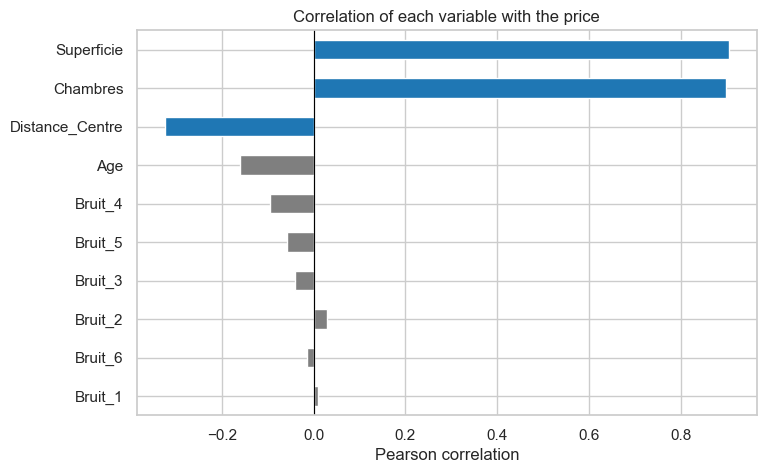

,Correlation with Price
Superficie,0.904
Chambres,0.899
Distance_Centre,-0.324
Age,-0.161
Bruit_4,-0.095
Bruit_5,-0.057
Bruit_3,-0.041
Bruit_2,0.030
Bruit_6,-0.015
Bruit_1,0.009


In [28]:
useful_threshold = 0.2

target_corr = (
    X_train_sel.join(y_train).corr()["Prix"]
    .drop("Prix")
    .sort_values(key=np.abs, ascending=False)
    .to_frame("Correlation with Price")
)

colors = ["tab:blue" if abs(v) >= useful_threshold else "tab:gray" for v in target_corr["Correlation with Price"]]
target_corr["Correlation with Price"].plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of each variable with the price")
plt.xlabel("Pearson correlation")
plt.gca().invert_yaxis()
plt.show()

target_corr.round(3)

In [29]:
useful_variables = target_corr.loc[target_corr["Correlation with Price"].abs() >= useful_threshold].index.to_list()
useless_variables = target_corr.loc[target_corr["Correlation with Price"].abs() < useful_threshold].index.to_list()


print("Useful variables  :", useful_variables)
print("Useless variables :", useless_variables)

X_train_final = X_train_sel[useful_variables]
X_test_final = X_test_sel[useful_variables]

X_train_final

Useful variables  : ['Superficie', 'Chambres', 'Distance_Centre']
Useless variables : ['Age', 'Bruit_4', 'Bruit_5', 'Bruit_3', 'Bruit_2', 'Bruit_6', 'Bruit_1']


,Superficie,Chambres,Distance_Centre
79,165.42,5.0,17.99
197,179.93,5.0,19.84
38,76.31,2.0,8.33
24,164.54,5.0,13.67
122,53.51,2.0,1.68
...,...,...,...
106,111.90,4.0,13.23
14,110.95,4.0,15.98
92,111.39,3.0,6.02
179,159.78,6.0,8.57


**Key takeaways**
- Pearson correlation only measures linear relationships.
- A redundant variable can be removed without loss of information.
- A variable whose correlation with the target is close to 0 is a candidate for removal.

## Part 3: Regularization

### 3.1 Principle

A linear regression fits the coefficients $\theta$ by minimizing the error. Nothing then prevents some coefficients from becoming very large, especially when two variables are redundant. **Regularization** adds to the cost function a **penalty** that limits the size of the coefficients.

- **Ridge** (L2 penalty):

$$
J(\theta) = \frac{1}{2n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \frac{\lambda}{2}\sum_{j=1}^{p}\theta_j^2
$$

- **Lasso** (L1 penalty):

$$
J(\theta) = \frac{1}{2n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \lambda\sum_{j=1}^{p}|\theta_j|
$$

The parameter $\lambda \geq 0$ controls the strength of the penalty. For $\lambda = 0$, we recover classical regression (OLS, ordinary least squares). The larger $\lambda$ is, the more the coefficients are shrunk.

The constant term (the intercept) is not penalized.

The difference between the two penalties comes from their shape: the L2 penalty shrinks all the coefficients progressively, whereas the L1 penalty can set some coefficients exactly to zero.

### 3.2 Data preparation

The penalties depend on the scale of the variables. A variable measured in square feet would have numerically smaller coefficients than in square meters, and would therefore be less penalized. We therefore **standardize** each variable: we subtract its mean and divide by its standard deviation.

The means and standard deviations are computed **on the training data only**, then applied to the test data. Otherwise, information from the test set would leak into the training.

In [30]:
def standardize(X_ref, X_other):
    col_mean = X_ref.mean(axis=0)
    col_std = X_ref.std(axis=0)
    return (X_ref - col_mean) / col_std, (X_other - col_mean) / col_std

def predict(X, theta, mean_y):
    return mean_y + X @ theta

def ols(X, y):
    return np.linalg.lstsq(X, y - y.mean(), rcond=None)[0]

Xa, Xt = standardize(X_train_sel.to_numpy(), X_test_sel.to_numpy())
ya, yt = y_train.to_numpy(), y_test.to_numpy()
mean_y = ya.mean()
n_train = len(ya)

theta_ols = ols(Xa, ya)

print("OLS coefficients:")
print(pd.Series(theta_ols, index=X_train_sel.columns).round(2))
print("\nTest MSE (OLS):", round(mse(yt, predict(Xt, theta_ols, mean_y)), 2))

OLS coefficients:
Superficie         76.27
Chambres           43.65
Age               -18.91
Distance_Centre   -38.44
Bruit_1             1.52
Bruit_2             2.12
Bruit_3             0.62
Bruit_4            -1.45
Bruit_5             1.61
Bruit_6             0.27
dtype: float64

Test MSE (OLS): 851.64


`Superficie` and `Chambres` are related (correlation of about 0.9), without being redundant. Their OLS coefficients are therefore less stable: another sample would give different values. This is the problem of **multicollinearity**.

### 3.3 Ridge

The minimum of the Ridge cost function can be computed directly:

$$
\hat{\theta} = (X^\top X + n\lambda I)^{-1} X^\top (y - \bar{y})
$$

Adding $n\lambda I$ makes the matrix invertible, even in the presence of multicollinearity. This is the central idea of Ridge.

In [31]:
def ridge(X, y, lam):
    n, p = X.shape
    yc = y - y.mean()
    return np.linalg.solve(X.T @ X + n * lam * np.eye(p), X.T @ yc)

### 3.4 Lasso

Lasso has no closed-form solution. We use **coordinate descent**: each coefficient is updated in turn, with the others held fixed. For a coefficient $\theta_j$, the update is:

$$
\theta_j \leftarrow S\!\left(\frac{1}{n} x_j^\top r_j,\ \lambda\right)
\qquad \text{with} \qquad
S(z, \lambda) = \text{sign}(z)\,\max(|z| - \lambda,\ 0)
$$

Here $r_j$ denotes the residual computed without variable $j$. Since the variables are standardized, $\frac{1}{n}x_j^\top x_j = 1$.

The function $S$ is called **soft thresholding**. It reduces the value by $\lambda$ and sets to zero any coefficient whose absolute value is below $\lambda$. This is the mechanism that produces exactly zero coefficients.

In [32]:
def lasso(X, y, lam, n_iter=1000):
    n, p = X.shape
    yc = y - y.mean()
    theta = np.zeros(p)
    for _ in range(n_iter):
        previous = theta.copy()
        for j in range(p):
            r = yc - X @ theta + X[:, j] * theta[j]
            rho = X[:, j] @ r / n
            theta[j] = np.sign(rho) * max(abs(rho) - lam, 0.0)
        if np.max(np.abs(theta - previous)) < 1e-8:
            break
    return theta

### 3.5 Checking with scikit-learn

Our code must give the same results as the reference library. The parameters correspond as follows: for Ridge, `alpha` equals $n\lambda$; for Lasso, `alpha` equals $\lambda$.

In [33]:
from sklearn.linear_model import Ridge, Lasso

lam_test = 0.05

ridge_sk = Ridge(alpha=n_train * lam_test).fit(Xa, ya)
lasso_sk = Lasso(alpha=lam_test, max_iter=100000, tol=1e-10).fit(Xa, ya)

print("Max difference Ridge:", np.max(np.abs(ridge_sk.coef_ - ridge(Xa, ya, lam_test))))
print("Max difference Lasso:", np.max(np.abs(lasso_sk.coef_ - lasso(Xa, ya, lam_test))))

Max difference Ridge: 1.4210854715202004e-14
Max difference Lasso: 6.908038585606846e-09


### 3.6 Regularization path

We compute the coefficients for a sequence of values of $\lambda$. The largest useful value is $\lambda_{\max}$: beyond it, all the Lasso coefficients are zero.

In [34]:
lam_max = np.max(np.abs(Xa.T @ (ya - mean_y))) / n_train
print(f"lambda_max = {lam_max:.3f}")
print("Lasso coefficients for lambda = lambda_max:", np.round(lasso(Xa, ya, lam_max), 4))

lambda_max = 116.667
Lasso coefficients for lambda = lambda_max: [ 0.  0. -0. -0.  0.  0. -0. -0. -0. -0.]


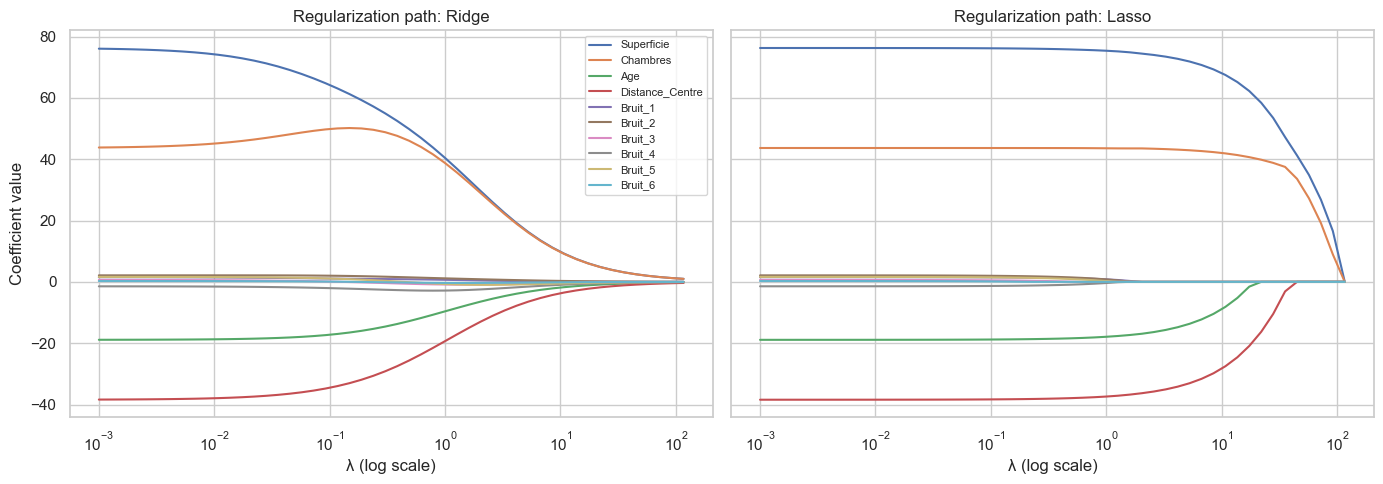

In [35]:
lambdas = np.logspace(-3, np.log10(lam_max), 50)
ridge_path = np.array([ridge(Xa, ya, l) for l in lambdas])
lasso_path = np.array([lasso(Xa, ya, l) for l in lambdas])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, path, title in zip(axes, [ridge_path, lasso_path], ["Ridge", "Lasso"]):
    ax.plot(lambdas, path)
    ax.set_xscale("log")
    ax.set_xlabel("λ (log scale)")
    ax.set_title(f"Regularization path: {title}")
axes[0].set_ylabel("Coefficient value")
axes[0].legend(X_train_sel.columns, fontsize=8)
plt.tight_layout()
plt.show()

With Ridge, the coefficients decrease progressively without ever reaching zero. With Lasso, the least useful coefficients reach zero one after another as $\lambda$ increases. Lasso therefore performs automatic variable selection.

### 3.7 Choosing $\lambda$ by cross-validation

The right $\lambda$ is not known in advance. We use **5-fold cross-validation**: the training data is split into 5 parts. Each part serves in turn as the validation set, while the other 4 are used for training. We choose the $\lambda$ that gives the smallest average error.

The test set remains untouched throughout this step.

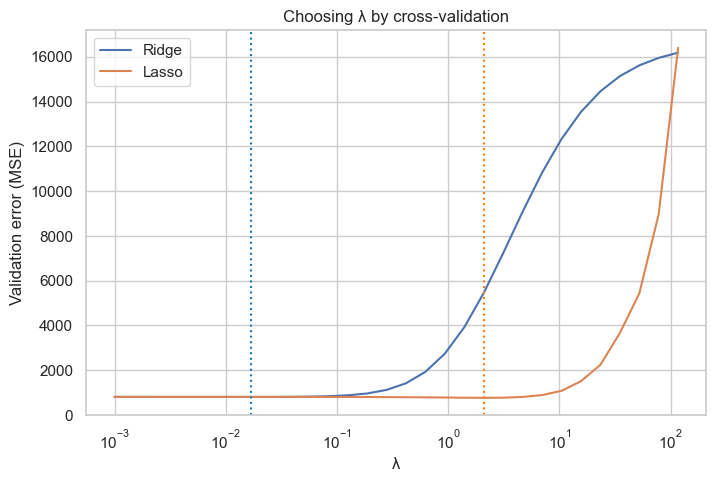

Selected λ for Ridge: 0.0167
Selected λ for Lasso: 2.0880


In [36]:
def validation_error(X, y, lam, method, k=5):
    errors = []
    for fold in np.array_split(np.arange(len(y)), k):
        mask = np.zeros(len(y), dtype=bool)
        mask[fold] = True
        X_fit, X_val = standardize(X[~mask], X[mask])
        y_fit, y_val = y[~mask], y[mask]
        theta = method(X_fit, y_fit, lam)
        errors.append(mse(y_val, predict(X_val, theta, y_fit.mean())))
    return np.mean(errors)

Xr, yr = X_train_sel.to_numpy(), y_train.to_numpy()
grid = np.logspace(-3, np.log10(lam_max), 30)

cv_ridge = [validation_error(Xr, yr, l, ridge) for l in grid]
cv_lasso = [validation_error(Xr, yr, l, lasso) for l in grid]

lam_ridge = grid[np.argmin(cv_ridge)]
lam_lasso = grid[np.argmin(cv_lasso)]

plt.semilogx(grid, cv_ridge, label="Ridge")
plt.semilogx(grid, cv_lasso, label="Lasso")
plt.axvline(lam_ridge, ls=":", color="tab:blue")
plt.axvline(lam_lasso, ls=":", color="tab:orange")
plt.xlabel("λ")
plt.ylabel("Validation error (MSE)")
plt.title("Choosing λ by cross-validation")
plt.legend()
plt.show()

print(f"Selected λ for Ridge: {lam_ridge:.4f}")
print(f"Selected λ for Lasso: {lam_lasso:.4f}")

The $\lambda$ selected for Ridge is very small. With 140 properties and variables that are only weakly related to each other, OLS is already stable: a strong penalty would only add bias. Ridge becomes more useful when there are many variables or when they are highly correlated.

### 3.8 Final comparison

We retrain each model on the whole training set with the chosen $\lambda$, then measure the error on the test set.

In [24]:
theta_ridge = ridge(Xa, ya, lam_ridge)
theta_lasso = lasso(Xa, ya, lam_lasso)
thetas = [theta_ols, theta_ridge, theta_lasso]

comparison = pd.DataFrame({
    "OLS": theta_ols,
    "Ridge": theta_ridge,
    "Lasso": theta_lasso,
}, index=X_train_sel.columns)

summary = pd.DataFrame({
    "Test MSE": [mse(yt, predict(Xt, t, mean_y)) for t in thetas],
    "Zero coefficients": [int(np.sum(np.isclose(t, 0))) for t in thetas],
}, index=["OLS", "Ridge", "Lasso"])

print("Coefficients (standardized variables):")
display(comparison.round(3))
print("Performance:")
display(summary.round(2))

Coefficients (standardized variables):


,OLS,Ridge,Lasso
Superficie,76.267,73.020,74.391
Chambres,43.654,45.877,43.509
Age,-18.906,-18.619,-16.870
Distance_Centre,-38.437,-37.652,-36.261
Bruit_1,1.523,1.381,0.000
Bruit_2,2.124,2.125,0.000
Bruit_3,0.622,0.500,0.000
Bruit_4,-1.447,-1.587,-0.000
Bruit_5,1.613,1.523,0.000
Bruit_6,0.273,0.234,-0.000


Performance:


,Test MSE,Zero coefficients
OLS,851.64,0
Ridge,862.94,0
Lasso,809.90,6


Ridge and OLS give almost the same coefficients and the same test error: in this example, the L2 penalty does not improve the prediction. Lasso sets three noise variables to zero (`Bruit_1`, `Bruit_4` and `Bruit_6`), and its test error is the lowest. `Bruit_2` and `Bruit_5` remain very close to zero, without being exactly zero. `Bruit_3` keeps a nonzero coefficient because it happens, by chance, to show an apparent relationship with the price in this sample. With 140 observations, this kind of chance effect is common. Lasso therefore keeps the variables that improve the prediction, not those that are perfectly useless.

**Key takeaways**
- Regularization adds a penalty to the error to limit the size of the coefficients.
- Ridge (L2) shrinks all the coefficients without setting them to zero. It is useful in the face of multicollinearity.
- Lasso (L1) can set coefficients to zero. It can therefore also be used to select variables.
- The parameter $\lambda$ is chosen by cross-validation, never on the test set.
- Variables must be standardized before regularizing.

## Part 4: Dimensionality reduction and PCA

### 4.1 Why reduce the dimension?

A dataset with many variables is hard to visualize, and some variables are redundant. **Dimensionality reduction** replaces the original variables with a small number of new variables that summarize the information.

### 4.2 The idea of PCA

**Principal component analysis** (PCA) looks for directions along which the data varies the most. These directions are the **principal components**. The first captures the largest variance, the second the largest remaining variance, and so on, while being orthogonal to each other.

On standardized data, the covariance matrix is $\Sigma = \frac{1}{n}X^\top X$. Its **eigenvectors** give the directions of the components, and its **eigenvalues** give the variance captured by each one. The share of explained variance is:

$$
\text{Share}_k = \frac{\lambda_k}{\sum_{j} \lambda_j}
$$

We compute the PCA from the standardized training data.

In [27]:
import numpy as np

M = np.array([[2, 6, 3, 1],
            [3, 2, 1, 7],
            [3, 4, 3, 2],
            [4, 2, 1, 5],
            [1, 2, 8, 5]]
)

n = len(M)



cov = M.T @ M / n

eigenvalues, eigenvectors = np.linalg.eigh(cov)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

variance_share = eigenvalues / eigenvalues.sum()

pca_table = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Explained variance (%)": 100 * variance_share,
    "Cumulative variance (%)": 100 * np.cumsum(variance_share),
}, index=[f"PC{i + 1}" for i in range(len(eigenvalues))])

pca_table.round(2)

,Eigenvalue,Explained variance (%),Cumulative variance (%)
PC1,44.29,76.09,76.09
PC2,7.76,13.34,89.43
PC3,5.75,9.89,99.32
PC4,0.40,0.68,100.00


The following chart (scree plot of the eigenvalues) helps choose the number of components to keep. We generally keep enough to reach 80% to 90% of the variance.

In [28]:
fig, ax = plt.subplots()
ax.bar(pca_table.index, pca_table["Explained variance (%)"], color="tab:blue", label="Per component")
ax.plot(pca_table.index, pca_table["Cumulative variance (%)"], "o-", color="tab:red", label="Cumulative")
ax.axhline(90, ls="--", color="gray")
ax.set_ylabel("%")
ax.set_title("Scree plot of eigenvalues")
ax.legend()
plt.show()

**Key takeaways**
- PCA creates new variables, linear combinations of the original variables, that are orthogonal to each other.
- The eigenvalues indicate the share of variance captured by each component.

## Part 5: Summary

| Method | Principle | Strengths | Limitations | When to use it |
|---|---|---|---|---|
| Correlation with the target | Keep the variables related to the price | Simple and fast | Linear relationships only, variables examined one at a time | First screening of the variables |
| Removing redundancies | Remove one variable out of two highly correlated ones | Simplifies the model | Threshold to choose | Before any regression |
| Ridge | L2 penalty | Stable in the presence of multicollinearity | Sets no variable to zero | Many variables related to each other |
| Lasso | L1 penalty | Selects the variables | May pick one of two related variables at random | Variable selection and prediction |
| PCA | New variables of maximal variance | Visualization, compression | Unsupervised, components hard to interpret | Visualizing, reducing noise |

**Working rule**: we standardize, we split training and test sets, we choose the parameters by cross-validation, and we judge the model only on the test set.